In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully.")

Libraries imported successfully.


In [26]:
from pathlib import Path

print("Current folder:", Path.cwd())

for file in Path.cwd().parents:
    print("Checking:", file)

Current folder: c:\Users\Shashiranjan kumar\OneDrive\Desktop\SWYNEX-Modeling-and-Evaluation\data\notebooks
Checking: c:\Users\Shashiranjan kumar\OneDrive\Desktop\SWYNEX-Modeling-and-Evaluation\data
Checking: c:\Users\Shashiranjan kumar\OneDrive\Desktop\SWYNEX-Modeling-and-Evaluation
Checking: c:\Users\Shashiranjan kumar\OneDrive\Desktop
Checking: c:\Users\Shashiranjan kumar\OneDrive
Checking: c:\Users\Shashiranjan kumar
Checking: c:\Users
Checking: c:\


In [ ]:
from pathlib import Path

for file in Path.home().rglob("netflix_titles_cleaned.csv"):
    print(file)

In [ ]:
from pathlib import Path
import pandas as pd

possible_paths = [
    Path("netflix_titles_cleaned.csv"),
    Path("../netflix_titles_cleaned.csv"),
    Path("../../netflix_titles_cleaned.csv"),
]

DATA_PATH = next(
    (path for path in possible_paths if path.exists()),
    None
)

if DATA_PATH is None:
    raise FileNotFoundError(
        "netflix_titles_cleaned.csv not found."
    )

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print("Dataset path:", DATA_PATH.resolve())
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

display(df.head())

Dataset loaded successfully.
Dataset path: C:\Users\Shashiranjan kumar\OneDrive\Desktop\SWYNEX-Modeling-and-Evaluation\data\netflix_titles_cleaned.csv
Rows: 8807
Columns: 12


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,Not Specified,United States,2021-09-25,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,Not Specified,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",Not Specified,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,Not Specified,Not Specified,Not Specified,2021-09-24,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,Not Specified,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [ ]:
model_df = df[
    ["type", "release_year", "rating", "country", "listed_in", "date_added"]
].copy()

model_df = model_df[model_df["type"].isin(["Movie", "TV Show"])].copy()

model_df["release_year"] = pd.to_numeric(
    model_df["release_year"], errors="coerce"
)

model_df["primary_country"] = (
    model_df["country"].fillna("Unknown").astype(str)
    .str.split(",").str[0].str.strip()
)

model_df["primary_genre"] = (
    model_df["listed_in"].fillna("Unknown").astype(str)
    .str.split(",").str[0].str.strip()
)

model_df["date_added"] = pd.to_datetime(
    model_df["date_added"], errors="coerce"
)

model_df["date_added_year"] = model_df["date_added"].dt.year

X = model_df[
    ["release_year", "date_added_year", "rating",
     "primary_country", "primary_genre"]
]

y = model_df["type"]

print("Features shape:", X.shape)
print("\nTarget distribution:")
print(y.value_counts())

Features shape: (8807, 5)

Target distribution:
type
Movie      6131
TV Show    2676
Name: count, dtype: int64


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("\nTraining target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (7045, 5)
Testing features: (1762, 5)

Training target: (7045,)
Testing target: (1762,)


In [ ]:

# Select required columns
model_df = df[
    ["type", "release_year", "rating", "country", "listed_in", "date_added"]
].copy()

# Keep only valid target classes
model_df = model_df[model_df["type"].isin(["Movie", "TV Show"])].copy()

# Prepare numerical feature
model_df["release_year"] = pd.to_numeric(
    model_df["release_year"], errors="coerce"
)

# Extract primary country and genre
model_df["primary_country"] = (
    model_df["country"].fillna("Unknown").astype(str).str.split(",").str[0].str.strip()
)

model_df["primary_genre"] = (
    model_df["listed_in"].fillna("Unknown").astype(str).str.split(",").str[0].str.strip()
)

# Extract year from date_added
model_df["date_added"] = pd.to_datetime(
    model_df["date_added"], errors="coerce"
)
model_df["date_added_year"] = model_df["date_added"].dt.year

# Features and target
X = model_df[
    ["release_year", "date_added_year", "rating",
     "primary_country", "primary_genre"]
]
y = model_df["type"]

print("Features and target prepared successfully.")
print("Feature shape:", X.shape)
print("\nTarget distribution:")
print(y.value_counts())


Features and target prepared successfully.
Feature shape: (8807, 5)

Target distribution:
type
Movie      6131
TV Show    2676
Name: count, dtype: int64


In [ ]:

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Train-test split completed successfully.")
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Training target distribution:")
print(y_train.value_counts())


Train-test split completed successfully.
Training samples: 7045
Testing samples: 1762
Training target distribution:
type
Movie      4904
TV Show    2141
Name: count, dtype: int64


In [ ]:

# Preprocessing for numerical and categorical features
numeric_features = ["release_year", "date_added_year"]
categorical_features = [
    "rating", "primary_country", "primary_genre"
]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Dummy baseline
dummy_model = DummyClassifier(strategy="most_frequent")
dummy_model.fit(X_train, y_train)

# Logistic Regression baseline
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

logistic_model.fit(X_train, y_train)

print("Both models trained successfully.")


Both models trained successfully.


In [ ]:

# Generate predictions
dummy_predictions = dummy_model.predict(X_test)
logistic_predictions = logistic_model.predict(X_test)

# Evaluate both models
models = {
    "Dummy Classifier": dummy_predictions,
    "Logistic Regression": logistic_predictions
}

for model_name, predictions in models.items():
    print(f"\n{model_name}")
    print("-" * 35)
    print("Accuracy:", round(accuracy_score(y_test, predictions), 4))
    print("Macro Precision:", round(
        float(precision_score(y_test, predictions, average="macro", zero_division=0)), 4
    ))
    print("Macro Recall:", round(
        float(recall_score(y_test, predictions, average="macro", zero_division=0)), 4
    ))
    print("Macro F1-score:", round(
        float(f1_score(y_test, predictions, average="macro", zero_division=0)), 4
    ))



Dummy Classifier
-----------------------------------
Accuracy: 0.6964
Macro Precision: 0.3482
Macro Recall: 0.5
Macro F1-score: 0.4105

Logistic Regression
-----------------------------------
Accuracy: 1.0
Macro Precision: 1.0
Macro Recall: 1.0
Macro F1-score: 1.0


Classification Report:
              precision    recall  f1-score   support

       Movie       1.00      1.00      1.00      1227
     TV Show       1.00      1.00      1.00       535

    accuracy                           1.00      1762
   macro avg       1.00      1.00      1.00      1762
weighted avg       1.00      1.00      1.00      1762



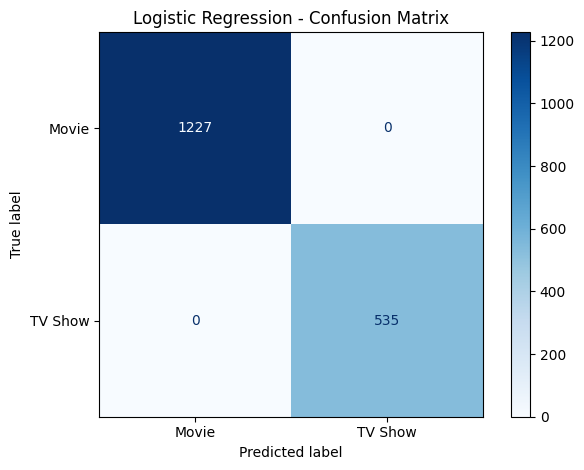

In [ ]:

# Detailed evaluation
print("Classification Report:")
print(classification_report(y_test, logistic_predictions, zero_division=0))

# Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    logistic_predictions,
    labels=["Movie", "TV Show"],
    cmap="Blues"
)

plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()


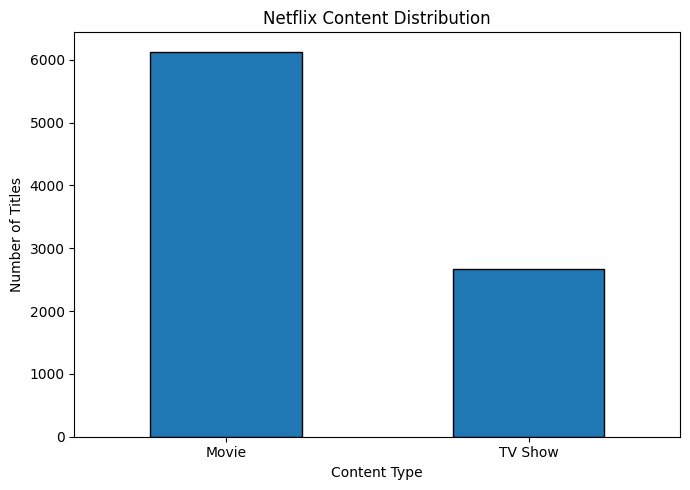

In [ ]:
plt.figure(figsize=(7, 5))

y.value_counts().plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Netflix Content Distribution")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
numeric_features = ["release_year", "date_added_year"]
categorical_features = [
    "rating", "primary_country", "primary_genre"
]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

logistic_model.fit(X_train, y_train)

logistic_predictions = logistic_model.predict(X_test)

print("Logistic Regression Accuracy:",
      round(accuracy_score(y_test, logistic_predictions), 4))

print("Logistic Regression Macro F1:",
    round(float(f1_score(y_test, logistic_predictions, average="macro", zero_division=0)), 4))

Logistic Regression Accuracy: 1.0
Logistic Regression Macro F1: 1.0


In [ ]:

# Check whether features strongly reveal the target
print("Target counts:")
print(y.value_counts())

print("\nRelease year by target:")
print(model_df.groupby("type")["release_year"].describe())

print("\nRating distribution by target:")
display(pd.crosstab(model_df["rating"], model_df["type"]))

print("\nPrimary genre distribution by target (top 10):")
display(pd.crosstab(
    model_df["primary_genre"], model_df["type"]
).head(10))


Target counts:
type
Movie      6131
TV Show    2676
Name: count, dtype: int64

Release year by target:
          count         mean       std     min     25%     50%     75%     max
type                                                                          
Movie    6131.0  2013.121514  9.678169  1942.0  2012.0  2016.0  2018.0  2021.0
TV Show  2676.0  2016.605755  5.740138  1925.0  2016.0  2018.0  2020.0  2021.0

Rating distribution by target:


type,Movie,TV Show
rating,,
66 min,1,0
74 min,1,0
84 min,1,0
G,41,0
NC-17,3,0
NR,75,5
Not Specified,2,2
PG,287,0
PG-13,490,0



Primary genre distribution by target (top 10):


type,Movie,TV Show
primary_genre,,
Action & Adventure,859,0
Anime Features,21,0
Anime Series,0,176
British TV Shows,0,253
Children & Family Movies,605,0
Classic & Cult TV,0,22
Classic Movies,80,0
Comedies,1210,0
Crime TV Shows,0,399


In [ ]:

# Test without primary_genre
X_no_genre = X.drop(columns=["primary_genre"])

X_train_ng, X_test_ng, y_train_ng, y_test_ng = train_test_split(
    X_no_genre,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

numeric_features_ng = ["release_year", "date_added_year"]
categorical_features_ng = [
    "rating", "primary_country"
]

preprocessor_ng = ColumnTransformer(transformers=[
    ("num", Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_features_ng),

    ("cat", Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features_ng)
])

logistic_no_genre = Pipeline(steps=[
    ("preprocessor", preprocessor_ng),
    ("classifier", LogisticRegression(max_iter=1000))
])

logistic_no_genre.fit(X_train_ng, y_train_ng)
predictions_ng = logistic_no_genre.predict(X_test_ng)

print("Accuracy without genre:",
      round(accuracy_score(y_test_ng, predictions_ng), 4))
print(
    "Macro F1 without genre:",
    round(float(f1_score(y_test_ng, predictions_ng, average="macro", zero_division=0)), 4)
)

print("\nClassification Report:")
print(classification_report(y_test_ng, predictions_ng, zero_division=0))


Accuracy without genre: 0.7446
Macro F1 without genre: 0.6582

Classification Report:
              precision    recall  f1-score   support

       Movie       0.77      0.90      0.83      1227
     TV Show       0.62      0.40      0.49       535

    accuracy                           0.74      1762
   macro avg       0.70      0.65      0.66      1762
weighted avg       0.73      0.74      0.73      1762



In [ ]:

# Compare baseline and validation model
results = pd.DataFrame([
    {
        "Model": "Dummy Classifier",
        "Accuracy": accuracy_score(y_test, dummy_predictions),
        "Macro F1": f1_score(
            y_test, dummy_predictions, average="macro", zero_division=0
        )
    },
    {
        "Model": "Logistic Regression (with genre)",
        "Accuracy": accuracy_score(y_test, logistic_predictions),
        "Macro F1": f1_score(
            y_test, logistic_predictions, average="macro", zero_division=0
        )
    },
    {
        "Model": "Logistic Regression (without genre)",
        "Accuracy": accuracy_score(y_test_ng, predictions_ng),
        "Macro F1": f1_score(
            y_test_ng, predictions_ng, average="macro", zero_division=0
        )
    }
])

display(results.round(4))


,Model,Accuracy,Macro F1
0,Dummy Classifier,0.6964,0.4105
1,Logistic Regression (with genre),1.0000,1.0000
2,Logistic Regression (without genre),0.7446,0.6582


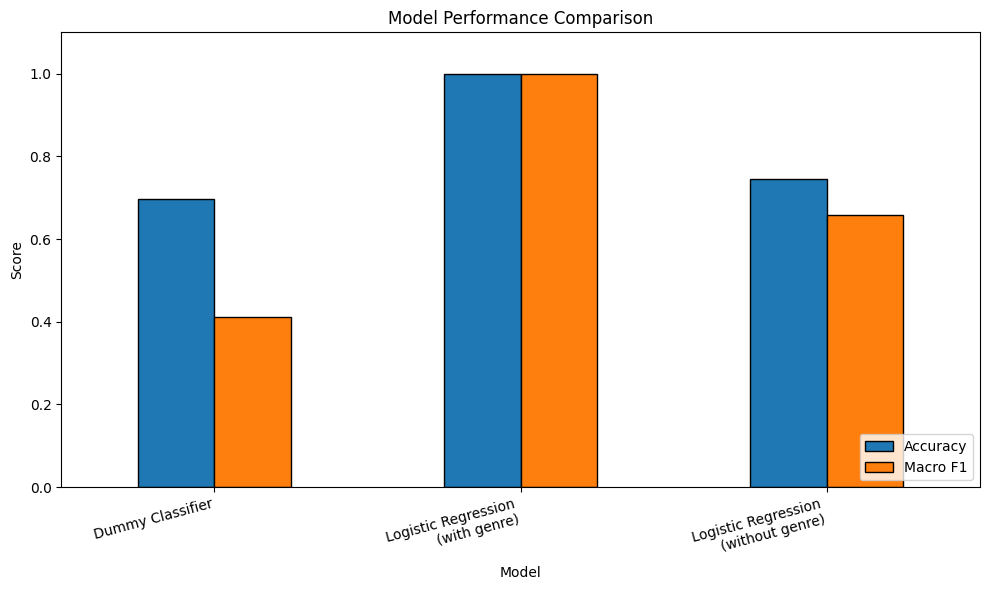

In [ ]:

results = pd.DataFrame({
    "Model": [
        "Dummy Classifier",
        "Logistic Regression\n(with genre)",
        "Logistic Regression\n(without genre)"
    ],
    "Accuracy": [0.6964, 1.0000, 0.7446],
    "Macro F1": [0.4105, 1.0000, 0.6582]
})

results.set_index("Model")[["Accuracy", "Macro F1"]].plot(
    kind="bar",
    figsize=(10, 6),
    edgecolor="black"
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1.1)
plt.xticks(rotation=15, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


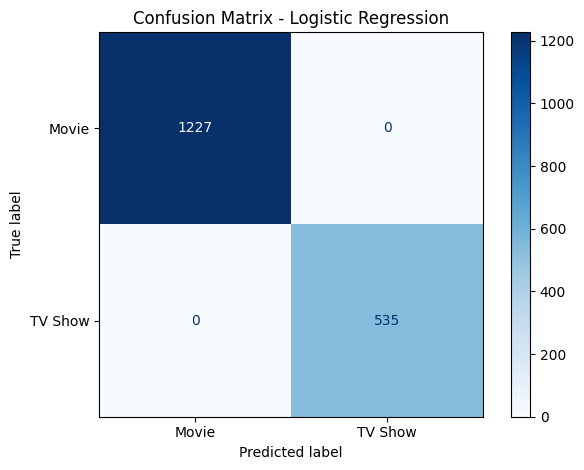

In [ ]:

ConfusionMatrixDisplay.from_predictions(
    y_test,
    logistic_predictions,
    labels=["Movie", "TV Show"],
    cmap="Blues",
    values_format="d"
)

plt.title("Confusion Matrix - Logistic Regression")
plt.tight_layout()
plt.show()


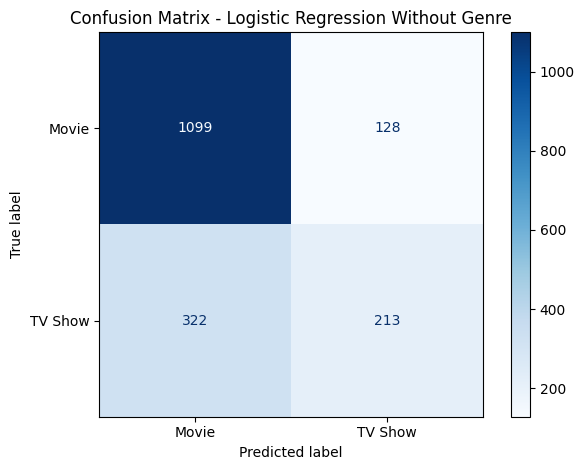

Classification Report (Without Genre):
              precision    recall  f1-score   support

       Movie       0.77      0.90      0.83      1227
     TV Show       0.62      0.40      0.49       535

    accuracy                           0.74      1762
   macro avg       0.70      0.65      0.66      1762
weighted avg       0.73      0.74      0.73      1762



In [ ]:

logistic_predictions_without_genre = logistic_no_genre.predict(X_test_ng)

ConfusionMatrixDisplay.from_predictions(
    y_test_ng,
    logistic_predictions_without_genre,
    labels=["Movie", "TV Show"],
    cmap="Blues",
    values_format="d"
)

plt.title("Confusion Matrix - Logistic Regression Without Genre")
plt.tight_layout()
plt.show()

print("Classification Report (Without Genre):")
print(classification_report(
    y_test,
    logistic_predictions_without_genre,
    labels=["Movie", "TV Show"],
    zero_division=0
))


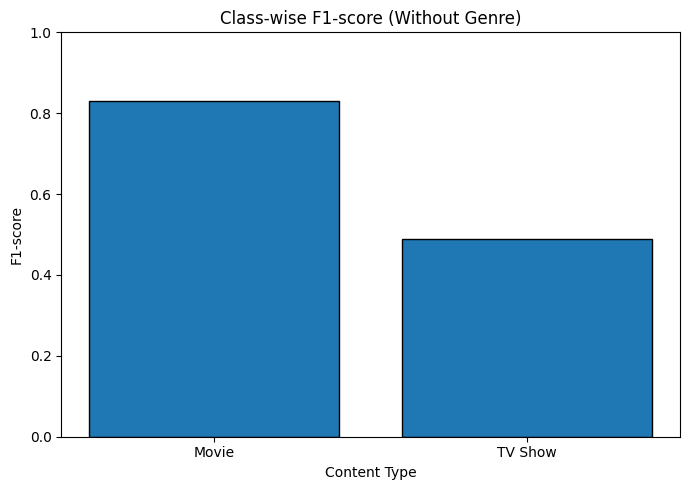

In [ ]:

class_scores = pd.DataFrame({
    "Content Type": ["Movie", "TV Show"],
    "F1-score": [0.83, 0.49]
})

plt.figure(figsize=(7, 5))

plt.bar(
    class_scores["Content Type"],
    class_scores["F1-score"],
    edgecolor="black"
)

plt.title("Class-wise F1-score (Without Genre)")
plt.xlabel("Content Type")
plt.ylabel("F1-score")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()


## Limitations

1. **Dataset scope:** The analysis uses a snapshot of Netflix titles and may not represent the current catalogue.
2. **Feature dependence:** Genre is strongly associated with content type, which resulted in perfect classification scores when included.
3. **Class imbalance:** The dataset contains more Movies than TV Shows, which affects model performance.
4. **Missing values:** Missing values were handled using imputation, which may affect predictions.
5. **Limited evaluation:** The models were evaluated using a single stratified train-test split. Cross-validation and external validation were not performed.
6. **Model limitations:** Logistic Regression without genre achieved 74.46% accuracy, but its recall for TV Shows was only 0.40.
7. **Not production-ready:** These models are educational baselines and require further testing before practical use.

## Conclusion

A Dummy Classifier and Logistic Regression models were evaluated on the Netflix Titles dataset. The Dummy Classifier achieved 69.64% accuracy and a macro F1-score of 0.4105. Logistic Regression with genre achieved 100% accuracy, but this result must be interpreted cautiously because genre is strongly associated with content type. Without genre, Logistic Regression achieved 74.46% accuracy and a macro F1-score of 0.6582. The results demonstrate the importance of feature selection and class-wise evaluation in machine learning.